# Notebook 09 — Final Experimental Evaluation & Evidence Audit

**Project:** Network Intrusion Detection with Feature-Tokenized CNN + SE + Multi-Head Self-Attention + train-only SMOTE.

This notebook **only consolidates already executed experiments**. It does not fit or optimize a model, select a checkpoint, or silently replace missing results with invented numbers.

Two distinct tasks, **never merged into one leaderboard**:

1. **CIC-IDS2017 (15 classes):** classical ML baselines from 04 V2 versus CNN-SMOTE verified in 05 Final; optional V7/V8 evidence.
2. **CTU-13 (binary BOTNET/NORMAL):** Notebook 06 baseline, 07 threshold/drift, and 08 cross-scenario robustness.

**Scientific limitations:** CIC pilot test was repeatedly inspected during development; CTU scenario 12 is exploratory. CTU reduced Parquet lacks timestamp and endpoint identifiers; do not claim graph or temporal results. **No fresh independent holdout is established by this notebook.**

## 0. Attach source outputs and configure paths

On Kaggle: **Add Input** the *saved output datasets* of Notebook 04 V2, 05 Final, 06, 07, 08. They should contain the CSV/JSON files listed in `INPUT_SPECS` below. Use Kaggle's *Save Version* to retain the report. If several copies of a source exist, set its directory explicitly to avoid mixing experiments.

Only pandas/numpy/matplotlib are required. No GPU, raw CIC/CTU dataset, or model checkpoint is required for this report.

In [105]:
from pathlib import Path
import json, os, warnings, hashlib, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOTS = [Path('/kaggle/input'), Path('/kaggle/working/nids_outputs'), Path('/mnt/data'), Path.cwd()]
# Override if Kaggle has multiple matching versions or nonstandard folder layouts.
SOURCE_DIRS = {
    'cic_ml': '',       # folder holding baseline_test_metrics.csv
    'cic_cnn_final': '',# folder holding pilot_test_metrics.json
    'cic_v7': '',       # optional
    'cic_v8': '',       # optional
    'ctu_06': '',       # folder holding scenario_holdout_metrics.json
    'ctu_07': '',       # folder holding selected_threshold_comparison.csv
    'ctu_08': '',       # folder holding final_test_metrics.json
}
INPUT_SPECS = {
    'cic_ml': ('baseline_test_metrics.csv', True),
    'cic_cnn_final': ('pilot_test_metrics.json', True),
    'cic_v7': ('final_test_metrics.json', False),
    'cic_v8': ('final_test_metrics.json', False),
    'ctu_06': ('scenario_holdout_metrics.json', True),
    'ctu_07': ('selected_threshold_comparison.csv', True),
    'ctu_08': ('final_test_metrics.json', True),
}
OUT = Path('/kaggle/working/nids_outputs/09_Final_Experimental_Evaluation' if Path('/kaggle/working').exists() else './nids_outputs/09_Final_Experimental_Evaluation')
OUT.mkdir(parents=True, exist_ok=True)
print('OUTPUT DIRECTORY:', OUT.resolve())

OUTPUT DIRECTORY: /kaggle/working/nids_outputs/09_Final_Experimental_Evaluation


## 1. Discover and audit source files

A source is accepted only when its directory can be resolved **unambiguously**. If a directory is missing or duplicated, the notebook marks it unavailable instead of guessing. The report can be generated partially, but the final completion audit will list missing evidence.

In [106]:
SOURCE_HINTS = {
    'cic_ml': ('04_ML_Baselines_V2', '04_ML_Baselines'),
    'cic_cnn_final': ('05_V10_SMOTE900_Deployment',),
    'cic_v7': ('05_V7_Web_Attack_Specialist',),
    'cic_v8': ('05_CNN_Ablation_V8_Tokenized',),
    'ctu_06': ('06_CTU_Flow_Baseline',),
    'ctu_07': ('07_CTU_CrossScenario_Drift',),
    'ctu_08': ('08_CTU_CrossScenario_Robustness',),
}
def discover_source(key, signature):
    manual = SOURCE_DIRS.get(key, '').strip()
    if manual:
        p=Path(manual)
        if not p.is_dir() or not (p/signature).is_file():
            raise FileNotFoundError(f'{key}: SOURCE_DIRS points to invalid directory {p}; required {signature}')
        return p, 'manual'
    matches=[]
    for root in ROOTS:
        if not root.exists(): continue
        for f in root.rglob(signature):
            folder=f.parent
            if not folder.is_dir(): continue
            if any(hint.lower() in str(folder).lower() for hint in SOURCE_HINTS[key]):
                matches.append(folder.resolve())
    unique=sorted(set(matches), key=str)
    if len(unique)==1: return unique[0], 'autodetected'
    if len(unique)==0: return None, 'missing'
    return None, 'ambiguous: '+str(len(unique))+' matching folders; set SOURCE_DIRS explicitly'

sources={}; rows=[]
for key,(required_file,mandatory) in INPUT_SPECS.items():
    folder,status=discover_source(key,required_file)
    sources[key]=folder
    rows.append({'source':key,'required_for_full_report':mandatory,'status':status,
                 'path':str(folder) if folder else '', 'signature':required_file})
source_audit=pd.DataFrame(rows)
source_audit.to_csv(OUT/'source_artifact_audit.csv',index=False)
display(source_audit)
missing=source_audit[(source_audit.required_for_full_report)&(source_audit.status.isin(['missing']))]
if len(missing): print('WARNING: Required inputs missing; results will be partial. Attach the saved Kaggle outputs.')
if source_audit.status.str.startswith('ambiguous').any(): print('WARNING: Multiple matches. Set SOURCE_DIRS explicitly, then rerun.')

,source,required_for_full_report,status,path,signature
0,cic_ml,True,autodetected,/kaggle/input/datasets/chienvoo/nids-outputs/n...,baseline_test_metrics.csv
1,cic_cnn_final,True,autodetected,/kaggle/working/nids_outputs/05_V10_SMOTE900_D...,pilot_test_metrics.json
2,cic_v7,False,autodetected,/kaggle/working/nids_outputs/05_V7_Web_Attack_...,final_test_metrics.json
3,cic_v8,False,autodetected,/kaggle/working/nids_outputs/05_CNN_Ablation_V...,final_test_metrics.json
4,ctu_06,True,autodetected,/kaggle/working/nids_outputs/06_CTU_Flow_Baseline,scenario_holdout_metrics.json
5,ctu_07,True,autodetected,/kaggle/working/nids_outputs/07_CTU_CrossScena...,selected_threshold_comparison.csv
6,ctu_08,True,autodetected,/kaggle/working/nids_outputs/08_CTU_CrossScena...,final_test_metrics.json


## 2. Load source artifacts and validate their shapes

Never infer an absent metric from another dataset. If an optional artifact is missing, preserve `NaN` and note it in the evidence ledger.

In [107]:
def load_csv(key,name,**kwargs):
    p=sources.get(key)
    return pd.read_csv(p/name,**kwargs) if p is not None and (p/name).is_file() else None

def load_json(key,name):
    p=sources.get(key)
    if p is None or not (p/name).is_file(): return None
    with (p/name).open(encoding='utf-8') as handle:return json.load(handle)

def pick(d,*names):
    if not isinstance(d,dict): return np.nan
    for name in names:
        if name in d:
            try:return float(d[name])
            except (ValueError,TypeError): pass
    return np.nan

def number(x):
    try:return float(x)
    except (ValueError,TypeError):return np.nan

def pct_col(frame,columns):
    f=frame.copy()
    for col in columns:
        if col in f.columns:f[col]=pd.to_numeric(f[col],errors='coerce')*100
    return f

ml=load_csv('cic_ml','baseline_test_metrics.csv')
ml_per=load_csv('cic_ml','baseline_test_per_class.csv')
cnn=load_json('cic_cnn_final','pilot_test_metrics.json')
cnn_per=load_csv('cic_cnn_final','pilot_test_per_class_metrics.csv')
cnn_cm=load_csv('cic_cnn_final','pilot_test_confusion_matrix.csv',index_col=0)
cnn_deploy=load_json('cic_cnn_final','deployment_manifest.json')
ctu6=load_json('ctu_06','scenario_holdout_metrics.json')
ctu7=load_csv('ctu_07','selected_threshold_comparison.csv')
ctu8=load_json('ctu_08','final_test_metrics.json')
ctu8_per=load_csv('ctu_08','test_classification_report.csv',index_col=0)
ctu8_cm=load_csv('ctu_08','test_confusion_matrix.csv',index_col=0)
print('CIC baseline rows:',0 if ml is None else len(ml),'| CIC CNN metrics:',bool(cnn))
print('CTU 06:',bool(ctu6),'| CTU 07:',ctu7 is not None,'| CTU 08:',bool(ctu8))

CIC baseline rows: 3 | CIC CNN metrics: True
CTU 06: True | CTU 07: True | CTU 08: True


## 3. CIC-IDS2017: fair comparison within the same feature split

Baseline results below must be from the **same 03B 60-feature split** as 05 Final. We verify the SHA if both manifests make it available; otherwise mark provenance as unverified. This notebook does not merge results from 19-feature pilot experiments into the main benchmark.

In [108]:
ml_manifest=load_json('cic_ml','experiment_manifest.json')
cnn_sha=(cnn_deploy or {}).get('split_sha256')
def locate_sha(obj):
    if not isinstance(obj,dict):return None
    for k in ['split_sha256','dataset_split_sha256','data_sha256','split_file_sha256']:
        if obj.get(k):return str(obj[k])
    # Nested manifest fields may carry the split hash.
    for val in obj.values():
        if isinstance(val,dict):
            found=locate_sha(val)
            if found:return found
    return None
ml_sha=locate_sha(ml_manifest)
sha_status=('MATCH' if cnn_sha and ml_sha and cnn_sha==ml_sha else
            'MISMATCH' if cnn_sha and ml_sha and cnn_sha!=ml_sha else 'NOT VERIFIED')
print('CIC SHA status:',sha_status)
if sha_status=='MISMATCH': raise ValueError('CIC 04 baseline and 05 final refer to different split hashes: do not compare them.')
if sha_status=='NOT VERIFIED': print('WARNING: Cannot independently establish common split SHA from supplied manifests; verify from Notebook 03B.')

cic_rows=[]
if ml is not None:
    for _,r in ml.iterrows():
        cic_rows.append({'model':str(r.get('model','unknown')), 'method':'ML baseline',
                         'accuracy':number(r.get('accuracy')),'macro_f1':number(r.get('macro_f1')),
                         'weighted_f1':number(r.get('weighted_f1')),
                         'attack_recall':number(r.get('attack_recall')),'fpr':number(r.get('fpr')),
                         'source':'04 V2 / baseline_test_metrics.csv','test_status':'exploratory pilot'})
if cnn is not None:
    cic_rows.append({'model':'Tokenized CNN + SE + MHSA + SMOTE900','method':'CNN proposed',
        'accuracy':pick(cnn,'accuracy'),'macro_f1':pick(cnn,'macro_f1'),
        'weighted_f1':pick(cnn,'weighted_f1'),'attack_recall':pick(cnn,'attack_recall'),
        'fpr':pick(cnn,'fpr'),'source':'05 Final / pilot_test_metrics.json',
        'test_status':'exploratory pilot'})
cic_table=pd.DataFrame(cic_rows,columns=['model','method','accuracy','macro_f1','weighted_f1','attack_recall','fpr','source','test_status'])
if not cic_table.empty:
    cic_table.to_csv(OUT/'cic_models_comparison.csv',index=False)
    display(pct_col(cic_table,['accuracy','macro_f1','weighted_f1','attack_recall','fpr']).round(2))
else:
    print('CIC comparison unavailable until 04 V2 and/or 05 Final artifacts are attached.')

CIC SHA status: MATCH


,model,method,accuracy,macro_f1,weighted_f1,attack_recall,fpr,source,test_status
0,LightGBM,ML baseline,97.85,90.64,97.76,99.92,0.59,04 V2 / baseline_test_metrics.csv,exploratory pilot
1,XGBoost,ML baseline,97.89,90.02,97.79,99.92,0.59,04 V2 / baseline_test_metrics.csv,exploratory pilot
2,RandomForest,ML baseline,97.37,83.80,97.35,99.79,1.85,04 V2 / baseline_test_metrics.csv,exploratory pilot
3,Tokenized CNN + SE + MHSA + SMOTE900,CNN proposed,95.20,81.08,95.10,99.27,5.10,05 Final / pilot_test_metrics.json,exploratory pilot


## 4. CIC 15-class Precision / Recall / F1 and Confusion Matrix

The CNN row is the **locked seed-43 SMOTE900 model**. Output includes class support, Precision, Recall, F1 and one-vs-rest Accuracy (which can be misleading for rare classes). All percentage columns are displayed as 0–100 for readability.

,class,support,precision,recall,f1-score,class_accuracy_ovr
0,BENIGN,1353.0,96.69,94.90,95.79,98.47
1,Bot,387.0,91.37,98.45,94.78,99.43
2,DDoS,681.0,100.00,98.68,99.33,99.88
3,DoS GoldenEye,681.0,97.96,98.83,98.39,99.70
4,DoS Hulk,585.0,98.30,98.97,98.64,99.78
5,DoS Slowhttptest,627.0,99.19,98.25,98.72,99.78
6,DoS slowloris,699.0,99.14,98.71,98.92,99.80
7,FTP-Patator,558.0,99.28,99.28,99.28,99.89
8,Heartbleed,2.0,100.00,50.00,66.67,99.99
9,Infiltration,8.0,100.00,50.00,66.67,99.95


,model,class,support,precision,recall,f1
12,RandomForest,Web Attack ï¿½ Brute Force,293,73.18,75.43,74.29
13,RandomForest,Web Attack ï¿½ Sql Injection,3,0.00,0.00,0.00
14,RandomForest,Web Attack ï¿½ XSS,134,45.38,44.03,44.70
27,XGBoost,Web Attack ï¿½ Brute Force,293,73.73,84.30,78.66
28,XGBoost,Web Attack ï¿½ Sql Injection,3,50.00,33.33,40.00
29,XGBoost,Web Attack ï¿½ XSS,134,50.00,35.07,41.23
42,LightGBM,Web Attack ï¿½ Brute Force,293,74.09,82.94,78.26
43,LightGBM,Web Attack ï¿½ Sql Injection,3,100.00,33.33,50.00
44,LightGBM,Web Attack ï¿½ XSS,134,48.48,35.82,41.20


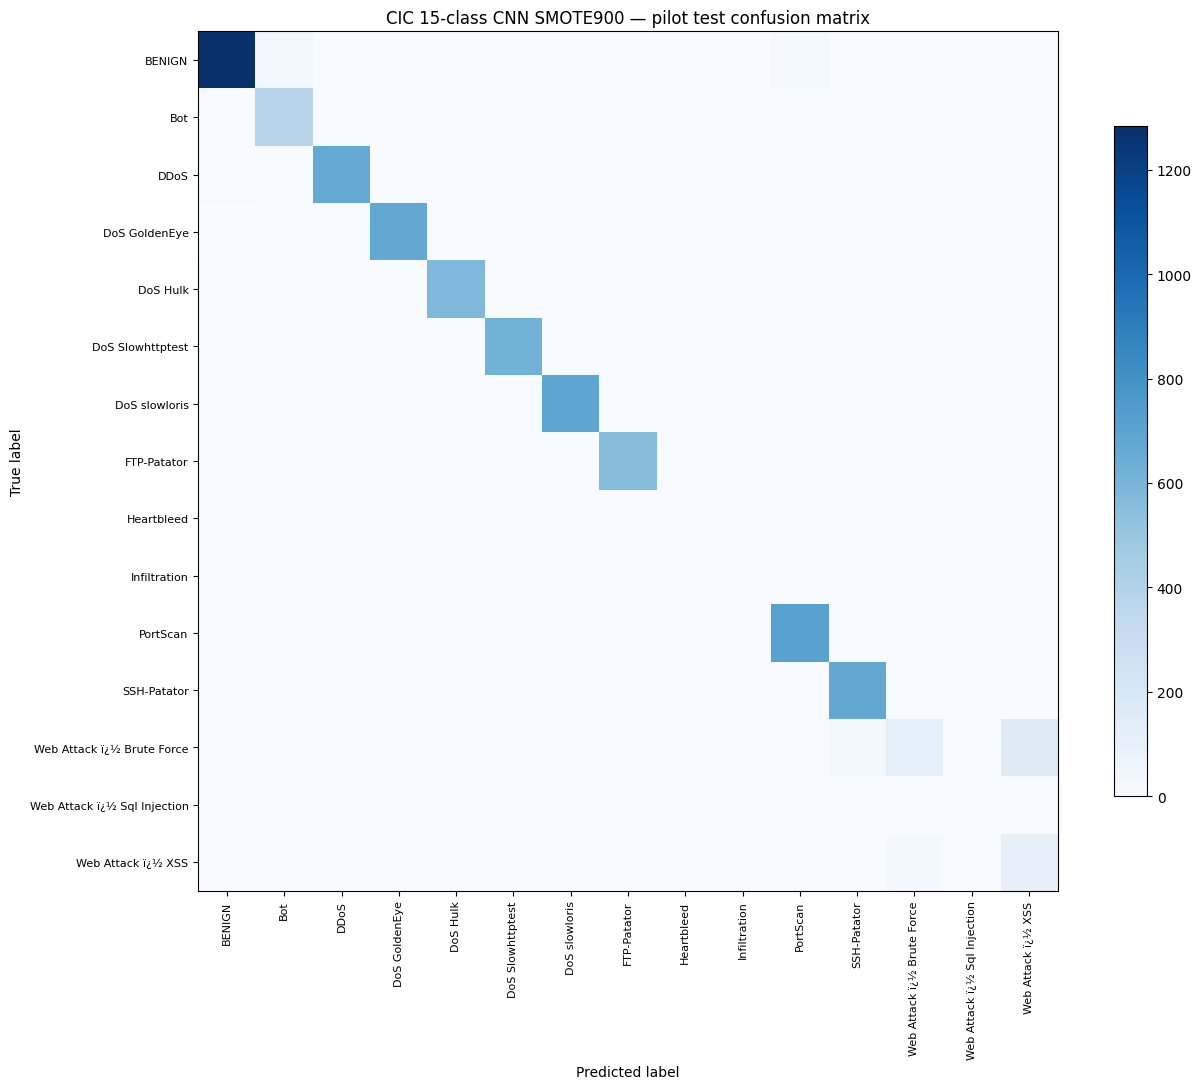

In [109]:
if cnn_per is not None:
    cnn_per=cnn_per.rename(columns={cnn_per.columns[0]:'class'}) if 'attack_class' not in cnn_per.columns and 'class' not in cnn_per.columns else cnn_per
    if 'attack_class' in cnn_per:cnn_per=cnn_per.rename(columns={'attack_class':'class'})
    keep=[col for col in ['class','support','precision','recall','f1-score','class_accuracy_ovr'] if col in cnn_per]
    cnn_per_out=cnn_per[keep].copy()
    cnn_per_out.to_csv(OUT/'cic_cnn_test_per_class.csv',index=False)
    display(pct_col(cnn_per_out,['precision','recall','f1-score','class_accuracy_ovr']).round(2))
else:print('Missing 05 Final / pilot_test_per_class_metrics.csv')

if ml_per is not None:
    ml_per.to_csv(OUT/'cic_baseline_test_per_class.csv',index=False)
    if 'class' in ml_per.columns:
        focus=ml_per[ml_per['class'].astype(str).str.contains('XSS|SQL|Brute',case=False,na=False)]
        display(pct_col(focus,['precision','recall','f1']).round(2))

if cnn_cm is not None:
    assert cnn_cm.shape[0]==cnn_cm.shape[1], 'CIC confusion matrix must be square'
    cnn_cm.to_csv(OUT/'cic_cnn_confusion_matrix.csv')
    fig,ax=plt.subplots(figsize=(13,11))
    im=ax.imshow(cnn_cm.to_numpy(),cmap='Blues')
    ax.set_xticks(range(len(cnn_cm.columns)),cnn_cm.columns,rotation=90,fontsize=8)
    ax.set_yticks(range(len(cnn_cm.index)),cnn_cm.index,fontsize=8)
    ax.set(xlabel='Predicted label',ylabel='True label',title='CIC 15-class CNN SMOTE900 — pilot test confusion matrix')
    fig.colorbar(im,ax=ax,fraction=.03);fig.tight_layout();fig.savefig(OUT/'cic_cnn_confusion_matrix.png',dpi=160);plt.show()
else:print('Missing 05 Final confusion matrix')

## 5. CIC ablation and imbalance study evidence

The ablation results were generated under earlier stages, sometimes using different configurations and seeds. They are **diagnostic evidence**, not proof of independent component effects unless matched-seed, matched-configuration comparisons are available. Stage V7 includes a LightGBM Web Attack Specialist; it is explicitly a **hybrid**, not a pure CNN.

In [110]:
optional_ablation=[]
for src,file,label in [
    ('cic_v8','ablation_single_seed.csv','V8 single-seed feature-tokenization ablation'),
    ('cic_v8','matched_seed_validation.csv','V8 matched-seed validation'),
    ('cic_v7','test_per_class_comparison.csv','V7 hybrid per-class comparison'),
]:
    tab=load_csv(src,file)
    if tab is not None:
        tab.to_csv(OUT/(src+'_'+file),index=False)
        optional_ablation.append({'experiment':label,'status':'AVAILABLE','rows':len(tab),'source':src+'/'+file})
    else:optional_ablation.append({'experiment':label,'status':'NOT ATTACHED','rows':0,'source':src+'/'+file})
display(pd.DataFrame(optional_ablation))
print('Interpretation: architecture comparisons require matching splits, seeds, configurations and selection rules.')

,experiment,status,rows,source
0,V8 single-seed feature-tokenization ablation,AVAILABLE,6,cic_v8/ablation_single_seed.csv
1,V8 matched-seed validation,AVAILABLE,3,cic_v8/matched_seed_validation.csv
2,V7 hybrid per-class comparison,AVAILABLE,15,cic_v7/test_per_class_comparison.csv


Interpretation: architecture comparisons require matching splits, seeds, configurations and selection rules.


## 6. CTU-13: compare the SAME binary Botnet task across Notebooks 06–08

Only **known NORMAL/BOTNET** records from scenario 12 are included. UNKNOWN/background are NOT treated as NORMAL. Scenario 12 is exploratory (already inspected earlier). For Notebook 07 the selected-threshold file may contain both validation/test: we explicitly extract `test` only.

In [111]:
ctu_rows=[]
if isinstance(ctu6,dict) and isinstance(ctu6.get('test'),dict):
    x=ctu6['test'];ctu_rows.append({'notebook':'06','model':'Random Forest',
        'threshold':np.nan,'accuracy':pick(x,'accuracy'),
        'botnet_precision':pick(x,'botnet_precision','precision'),
        'botnet_recall':pick(x,'botnet_recall','recall'),
        'botnet_f1':pick(x,'botnet_f1','f1'),
        'macro_f1':pick(x,'macro_f1'),'fpr':pick(x,'fpr'),
        'source':'06 / scenario_holdout_metrics.json'})
if ctu7 is not None:
    print('CTU 07 comparison columns:',list(ctu7.columns))
    chosen=ctu7.copy()
    for col in ['split','dataset','partition']:
        if col in chosen.columns:
            chosen=chosen[chosen[col].astype(str).str.lower().str.contains('test')]
            break
    if len(chosen)==1:
        x=chosen.iloc[0].to_dict()
        ctu_rows.append({'notebook':'07','model':'RF + validation-selected threshold',
            'threshold':number(x.get('threshold')),
            'accuracy':pick(x,'accuracy'),'botnet_precision':pick(x,'botnet_precision','precision'),
            'botnet_recall':pick(x,'botnet_recall','recall'),
            'botnet_f1':pick(x,'botnet_f1','f1'),
            'macro_f1':pick(x,'macro_f1'),'fpr':pick(x,'fpr'),
            'source':'07 / selected_threshold_comparison.csv'})
    else:print('CTU 07 ambiguous test row: skipped rather than guessing')
if isinstance(ctu8,dict):
    x=ctu8.get('metrics',{})
    ctu_rows.append({'notebook':'08','model':str(ctu8.get('model','unknown')),
        'threshold':number(ctu8.get('threshold')),
        'accuracy':pick(x,'accuracy'),'botnet_precision':pick(x,'botnet_precision','precision'),
        'botnet_recall':pick(x,'botnet_recall','recall'),
        'botnet_f1':pick(x,'botnet_f1','f1'),
        'macro_f1':pick(x,'macro_f1'),'fpr':pick(x,'fpr'),
        'source':'08 / final_test_metrics.json'})
ctu_table=pd.DataFrame(ctu_rows,columns=['notebook','model','threshold','accuracy','botnet_precision','botnet_recall','botnet_f1','macro_f1','fpr','source'])
if not ctu_table.empty:
    ctu_table.to_csv(OUT/'ctu_test_models_comparison.csv',index=False)
    display(pct_col(ctu_table,['accuracy','botnet_precision','botnet_recall','botnet_f1','macro_f1','fpr']).round(2))
else:print('CTU outputs 06/07/08 missing; attach the saved output datasets.')

CTU 07 comparison columns: ['split', 'scenario', 'threshold', 'n', 'accuracy', 'botnet_precision', 'botnet_recall', 'botnet_f1', 'macro_f1', 'fpr', 'TN', 'FP', 'FN', 'TP']


,notebook,model,threshold,accuracy,botnet_precision,botnet_recall,botnet_f1,macro_f1,fpr,source
0,06,Random Forest,NaN,76.41,34.11,5.15,8.95,47.70,2.89,06 / scenario_holdout_metrics.json
1,07,RF + validation-selected threshold,0.58,76.54,30.73,3.35,6.04,46.32,2.19,07 / selected_threshold_comparison.csv
2,08,HistGradientBoosting,0.02,82.41,57.45,84.25,68.32,78.07,18.13,08 / final_test_metrics.json


## 7. CTU per-class report, confusion matrix and drift evidence

,class,precision,recall,f1-score,support
0,NORMAL,94.71,81.87,87.82,6885.00
1,BOTNET,57.45,84.25,68.32,2000.00
2,accuracy,82.41,82.41,82.41,0.82
3,macro avg,76.08,83.06,78.07,8885.00
4,weighted avg,86.32,82.41,83.43,8885.00


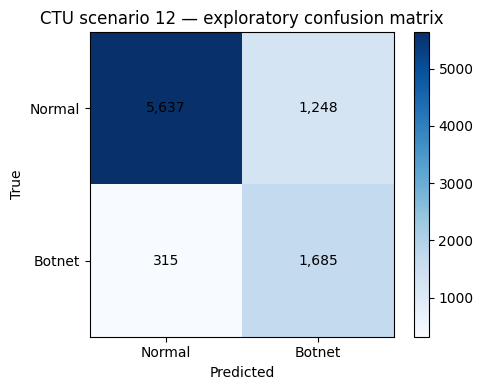

CHECK FROM CONFUSION MATRIX: {'accuracy': np.float64(0.8240855374226224), 'botnet_precision': np.float64(0.5744971019434026), 'botnet_recall': np.float64(0.8425), 'fpr': np.float64(0.1812636165577342)}


,feature,type,comparison,psi,ks_stat,js_divergence,train_median,other_median
0,dur,numeric,train_vs_validation,1.679767,0.255580,NaN,0.021872,0.001028
1,dur,numeric,train_vs_test,0.190466,0.113975,NaN,0.021872,0.035822
2,stos,numeric,train_vs_validation,0.000000,0.000000,NaN,0.000000,0.000000
3,stos,numeric,train_vs_test,0.000000,0.000000,NaN,0.000000,0.000000
4,dtos,numeric,train_vs_validation,0.000000,0.000000,NaN,0.000000,0.000000
5,dtos,numeric,train_vs_test,0.000000,0.000121,NaN,0.000000,0.000000
6,tot_pkts,numeric,train_vs_validation,2.505828,0.342907,NaN,2.000000,2.000000
7,tot_pkts,numeric,train_vs_test,0.011127,0.033475,NaN,2.000000,2.000000
8,tot_bytes,numeric,train_vs_validation,1.259183,0.386186,NaN,366.000000,400.000000
9,tot_bytes,numeric,train_vs_test,0.124241,0.079498,NaN,366.000000,412.000000


In [112]:
if ctu8_per is not None:
    ctu8_per.to_csv(OUT/'ctu_08_test_per_class.csv')
    display(pct_col(ctu8_per.reset_index().rename(columns={'index':'class'}),['precision','recall','f1-score']).round(2))
if ctu8_cm is not None:
    assert ctu8_cm.shape==(2,2),'Expected 2x2 CTU confusion matrix'
    ctu8_cm.to_csv(OUT/'ctu_08_confusion_matrix.csv')
    fig,ax=plt.subplots(figsize=(5,4)); mat=ctu8_cm.to_numpy(dtype=float)
    im=ax.imshow(mat,cmap='Blues')
    ax.set_xticks([0,1],['Normal','Botnet']);ax.set_yticks([0,1],['Normal','Botnet'])
    ax.set(xlabel='Predicted',ylabel='True',title='CTU scenario 12 — exploratory confusion matrix')
    for (i,j),v in np.ndenumerate(mat):ax.text(j,i,f'{int(v):,}',ha='center',va='center')
    fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/'ctu_confusion_matrix.png',dpi=160);plt.show()
    tn,fp,fn,tp=mat.ravel()
    computed={'accuracy':(tn+tp)/mat.sum(),'botnet_precision':tp/(tp+fp) if tp+fp else 0,
       'botnet_recall':tp/(tp+fn) if tp+fn else 0,'fpr':fp/(fp+tn) if fp+tn else 0}
    print('CHECK FROM CONFUSION MATRIX:',computed)
    if ctu8 and ctu8.get('metrics'):
        for k,val in computed.items():
            recorded=pick(ctu8['metrics'],k,'precision' if k=='botnet_precision' else k,'recall' if k=='botnet_recall' else k)
            if not np.isnan(recorded):assert abs(recorded-val)<1e-5,(k,recorded,val)
else:print('Missing 08 confusion matrix')
drift=load_csv('ctu_07','feature_distribution_drift.csv')
if drift is not None:
    drift.to_csv(OUT/'ctu_07_distribution_drift.csv',index=False)
    display(drift.head(12))

## 8. Plots: only compare models within one dataset

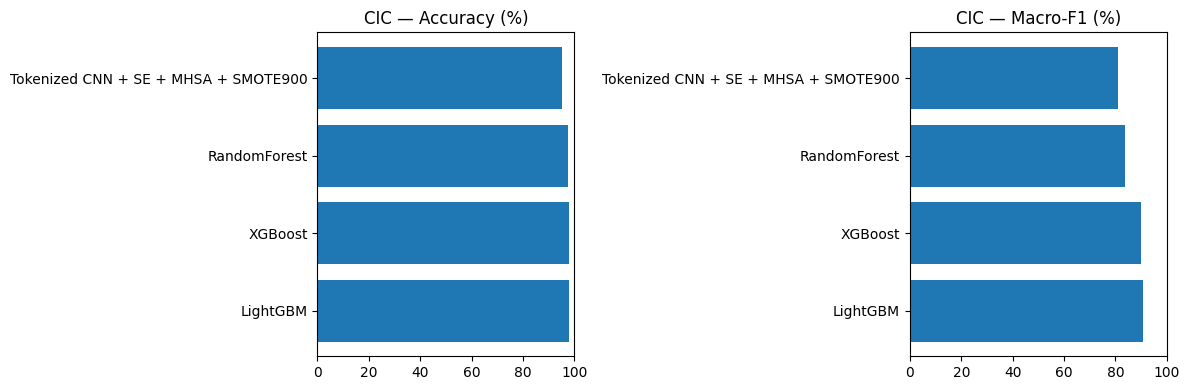

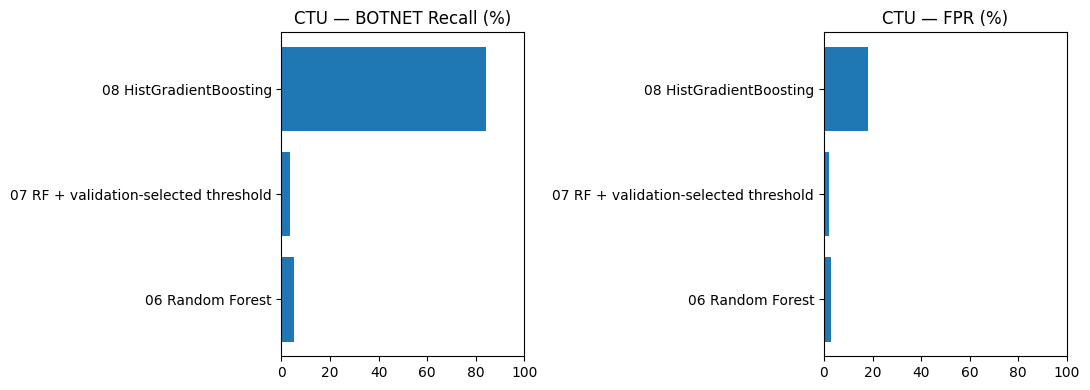

In [113]:
if not cic_table.empty:
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    models=cic_table['model'].astype(str)
    axes[0].barh(models,cic_table['accuracy']*100);axes[0].set_title('CIC — Accuracy (%)');axes[0].set_xlim(0,100)
    axes[1].barh(models,cic_table['macro_f1']*100);axes[1].set_title('CIC — Macro-F1 (%)');axes[1].set_xlim(0,100)
    fig.tight_layout();fig.savefig(OUT/'cic_comparison.png',dpi=150);plt.show()
if not ctu_table.empty:
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    models=ctu_table['notebook'].astype(str)+' '+ctu_table['model'].astype(str)
    axes[0].barh(models,ctu_table['botnet_recall']*100);axes[0].set_title('CTU — BOTNET Recall (%)');axes[0].set_xlim(0,100)
    axes[1].barh(models,ctu_table['fpr']*100);axes[1].set_title('CTU — FPR (%)');axes[1].set_xlim(0,100)
    fig.tight_layout();fig.savefig(OUT/'ctu_comparison.png',dpi=150);plt.show()

## 9. Evidence completeness, limitations and machine-readable final summary

This cell records whether key evidence was actually loaded. **A present notebook is not sufficient**: its *saved outputs* must be attached. All results on the original pilot splits remain exploratory; independent holdout is a future requirement.

In [114]:
checks=[
 ('CIC baseline metrics',ml is not None),
 ('CIC baseline per-class',ml_per is not None),
 ('CIC final test metrics',cnn is not None),
 ('CIC final per-class',cnn_per is not None),
 ('CIC final confusion matrix',cnn_cm is not None),
 ('CTU 06 test metrics',bool(ctu6)),
 ('CTU 07 selected-threshold comparison',ctu7 is not None),
 ('CTU 08 test metrics',bool(ctu8)),
 ('CTU 08 per-class',ctu8_per is not None),
 ('CTU 08 confusion matrix',ctu8_cm is not None),
]
audit=pd.DataFrame([{'evidence':name,'status':'AVAILABLE' if ok else 'MISSING'} for name,ok in checks])
audit.to_csv(OUT/'final_evidence_completeness.csv',index=False)
display(audit)
summary={
 'report':'09_Final_Experimental_Evaluation',
 'generated_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
 'cic_task':'15-class CIC-IDS2017 on 03B expanded 60-feature pilot split',
 'ctu_task':'CTU-13 scenario 5/11/12 flow-only binary known-label classification',
 'cic_provenance_sha_status':sha_status,
 'cic_models':cic_table.replace({np.nan:None}).to_dict(orient='records'),
 'ctu_models':ctu_table.replace({np.nan:None}).to_dict(orient='records'),
 'evidence':audit.to_dict(orient='records'),
 'scientific_limitations':[
  'CIC pilot test inspected repeatedly in earlier experimentation; not independent final holdout',
  'CTU scenario 12 inspected and diagnostic R1 uses test scenario as source in exploratory analyses',
  'CTU known-label evaluation excludes UNKNOWN/BACKGROUND; performance does not cover unlabeled flows',
  'CTU reduced Parquet lacks IP/timestamp; graph, beaconing, and temporal claims unsupported',
  'CIC and CTU scores represent different datasets/tasks and cannot be placed on one common leaderboard',
  'Live Linux packet-to-60-feature CIC extraction and independent deployment evaluation not yet validated'
 ],
}
(OUT/'final_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str),encoding='utf8')
print('ARTIFACTS:', len(list(OUT.iterdir())),'files in',OUT)
for f in sorted(OUT.iterdir()): print(' -',f.name)

,evidence,status
0,CIC baseline metrics,AVAILABLE
1,CIC baseline per-class,AVAILABLE
2,CIC final test metrics,AVAILABLE
3,CIC final per-class,AVAILABLE
4,CIC final confusion matrix,AVAILABLE
5,CTU 06 test metrics,AVAILABLE
6,CTU 07 selected-threshold comparison,AVAILABLE
7,CTU 08 test metrics,AVAILABLE
8,CTU 08 per-class,AVAILABLE
9,CTU 08 confusion matrix,AVAILABLE


ARTIFACTS: 18 files in /kaggle/working/nids_outputs/09_Final_Experimental_Evaluation
 - cic_baseline_test_per_class.csv
 - cic_cnn_confusion_matrix.csv
 - cic_cnn_confusion_matrix.png
 - cic_cnn_test_per_class.csv
 - cic_comparison.png
 - cic_models_comparison.csv
 - cic_v7_test_per_class_comparison.csv
 - cic_v8_ablation_single_seed.csv
 - cic_v8_matched_seed_validation.csv
 - ctu_07_distribution_drift.csv
 - ctu_08_confusion_matrix.csv
 - ctu_08_test_per_class.csv
 - ctu_comparison.png
 - ctu_confusion_matrix.png
 - ctu_test_models_comparison.csv
 - final_evidence_completeness.csv
 - final_summary.json
 - source_artifact_audit.csv


## 10. Concise conclusions for the project report

- **CIC:** Report the 15-class Accuracy, per-class Precision/Recall/F1, Macro-F1, FPR and confusion matrix for the validation-selected CNN–SE–Attention + SMOTE900 checkpoint, alongside RF/XGBoost/LightGBM on the same split. Explicitly discuss XSS-versus-Web-Brute-Force errors and rare SQL Injection.
- **CTU:** Report scenario holdout performance separately. A lower threshold can improve Botnet Recall at the cost of false alarms; results vary materially between scenarios.
- **Ablation:** Do not claim additive benefits from SE and Attention without matched-condition evidence. Hybrid V7 uses LightGBM and should be labeled hybrid, not pure CNN.
- **Deployment:** A saved inference checkpoint is not a validated live NIDS. Extraction of the exact 60 CIC features from PCAP/live flows and independent holdout evaluation remain outstanding.

**Done criteria for this notebook:** Every required evidence row is `AVAILABLE`, CIC SHA is `MATCH` (when hashes are included), both confusion matrices are verified, and final summary/figures are saved. Missing evidence must be disclosed rather than imputed.